#Versuch Nachkommastellen

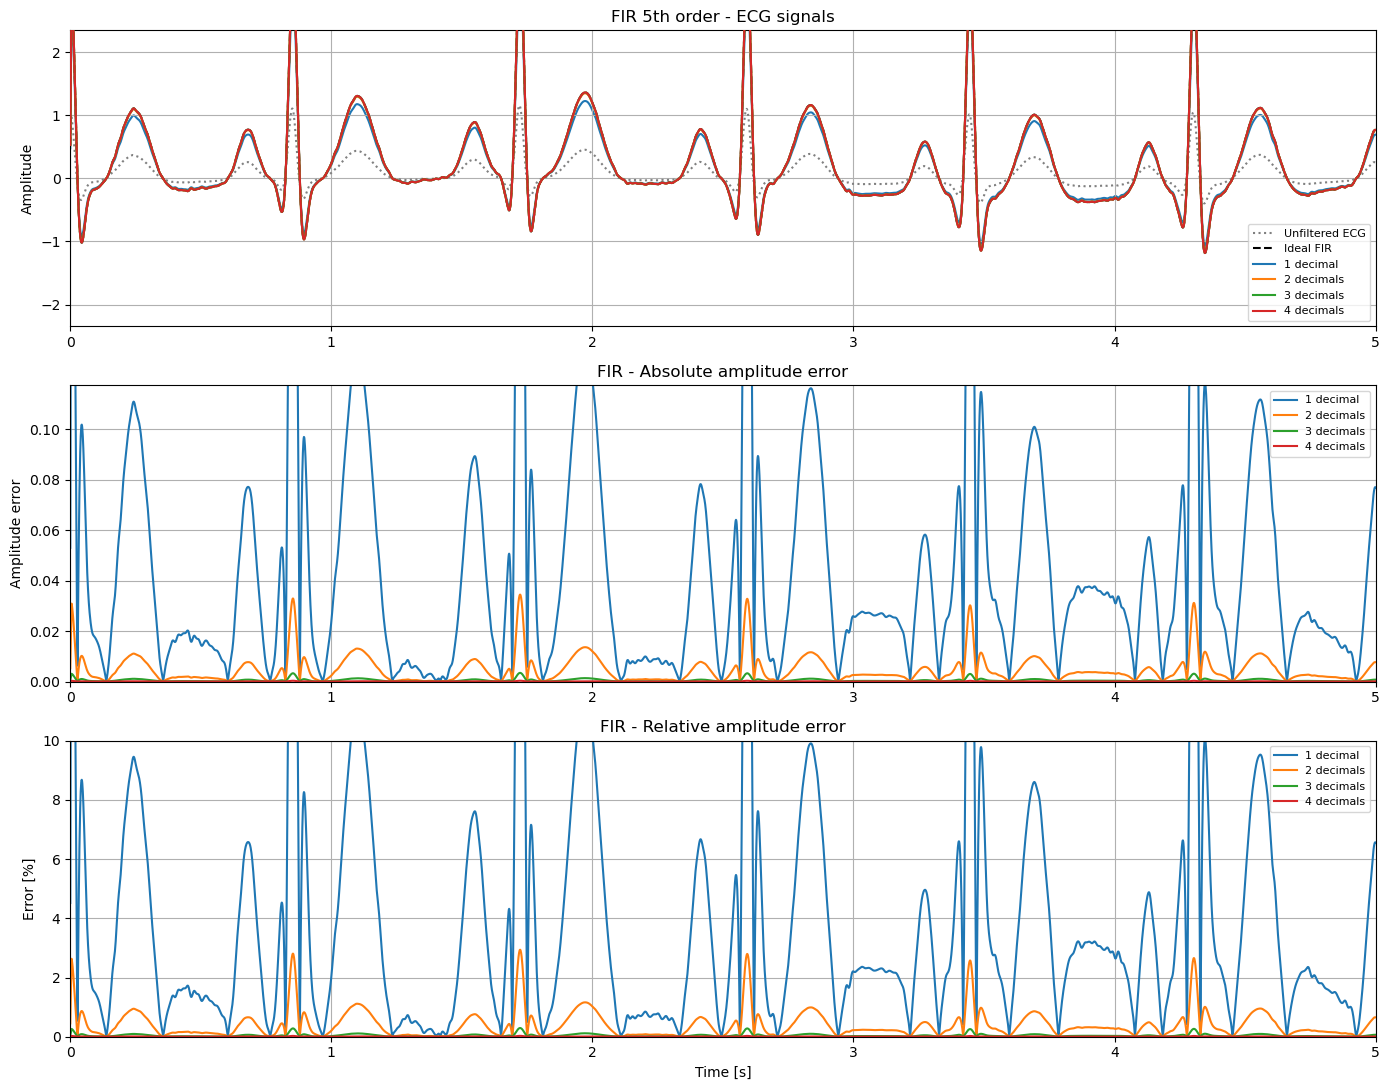


FIR - 5th order
Decimals | Max amplitude error | Max relative error [%]
   1     |      0.349656       |        29.8079        
   2     |      0.034966       |         2.9808        
   3     |      0.003497       |         0.2981        
   4     |      0.000350       |         0.0298        


In [ ]:

#-------------------------------------------------------
#-- Titel       : Fehlerabschätzung für die Nachkommastellen
#-------------------------------------------------------
#-- Projekt     : Vorabklärung Nachkommastellen
#-- Filename    : Versuch_Nachkommastellen.ipynb
#-- Autor       : Stefan Foltrauer
#-- Letze Änderungen : 17.10.2026
#-------------------------------------------------------
#-- Beschreibung: 
#-- Die Konfigurationsschnittstelle wird Fixpunktwerte in Zweierkomplementdarstellung erhalten.
#-- Um eine Abschätzung des Fehlers machen zu können wurde ein Testskript mit ChatGPT erstellt, welches jeweils den maximalen Fehler feststellen soll.
#-- Die Annahme ist das der Bediener den Filterkoeffizient jeweils rundet. Um den maximalen Fehler herauszufinden werden Filter mit dem 
#-- maximalen Rundungsfehler für eine Unterschiedliche Zahl von Nachkommastellen erstellt. 
#-- Ein generisches EKG Signal wird dann mit diesen Filtern gefiltert und es wird der prozentuale Fehler mittels eines Vergleichs festgestellt.
#-- Es ist klar, dass der Rundungsfehler nicht der einzige Fehler sein wird, es gibt aber es hilft bei der Einschätzung des
#-- möglichen Fehlers je nach Nachkommastelle. Es wurden bewusst nur FIR Filter betrachtet, da diese in der Regel stabil sind und 
#-- keine zusätzlichen Fehler durch Instabilität entstehen kann.
#-------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy.signal import lfilter

# --------------------------------------------------
# Generate ECG
# --------------------------------------------------

fs = 1000

ecg = nk.ecg_simulate(
    duration=20,
    sampling_rate=fs,
    heart_rate=70,
    random_state=42
)

time = np.arange(len(ecg)) / fs
reference = np.max(np.abs(ecg))

# --------------------------------------------------
# FIR filter - 5th order
# --------------------------------------------------

# 6 coefficients = 5th order
b = np.full(6, 0.5)

# Ideal FIR filter
y_fir_ideal = lfilter(b, [1], ecg)

# FIR filters with maximum coefficient errors
y_fir_1 = lfilter(b - 0.05, [1], ecg)
y_fir_2 = lfilter(b - 0.005, [1], ecg)
y_fir_3 = lfilter(b - 0.0005, [1], ecg)
y_fir_4 = lfilter(b - 0.00005, [1], ecg)

# Absolute amplitude errors
e_fir_1 = np.abs(y_fir_1 - y_fir_ideal)
e_fir_2 = np.abs(y_fir_2 - y_fir_ideal)
e_fir_3 = np.abs(y_fir_3 - y_fir_ideal)
e_fir_4 = np.abs(y_fir_4 - y_fir_ideal)

# --------------------------------------------------
# Plots
# --------------------------------------------------

fig, ax = plt.subplots(3, 1, figsize=(14, 11))

# FIR - ECG signals
ax[0].plot(time, ecg, ":", color="gray", label="Unfiltered ECG")
ax[0].plot(time, y_fir_ideal, "k--", label="Ideal FIR")

ax[0].plot(time, y_fir_1, label="1 decimal", zorder=1)
ax[0].plot(time, y_fir_2, label="2 decimals", zorder=2)
ax[0].plot(time, y_fir_3, label="3 decimals", zorder=3)
ax[0].plot(time, y_fir_4, label="4 decimals", zorder=4)

ax[0].set_title("FIR 5th order - ECG signals")
ax[0].set_ylabel("Amplitude")
ax[0].set_ylim(-2*reference, 2*reference)

# FIR - Absolute error
ax[1].plot(time, e_fir_1, label="1 decimal")
ax[1].plot(time, e_fir_2, label="2 decimals")
ax[1].plot(time, e_fir_3, label="3 decimals")
ax[1].plot(time, e_fir_4, label="4 decimals")

ax[1].set_title("FIR - Absolute amplitude error")
ax[1].set_ylabel("Amplitude error")
ax[1].set_ylim(0, 0.1*reference)

# FIR - Relative error
ax[2].plot(time, 100*e_fir_1/reference, label="1 decimal")
ax[2].plot(time, 100*e_fir_2/reference, label="2 decimals")
ax[2].plot(time, 100*e_fir_3/reference, label="3 decimals")
ax[2].plot(time, 100*e_fir_4/reference, label="4 decimals")

ax[2].set_title("FIR - Relative amplitude error")
ax[2].set_ylabel("Error [%]")
ax[2].set_ylim(0, 10)
ax[2].set_xlabel("Time [s]")

# General formatting
for axes in ax:
    axes.set_xlim(0, 5)
    axes.grid()
    axes.legend(fontsize=8)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# Maximum errors
# --------------------------------------------------

print("\nFIR - 5th order")
print("Decimals | Max amplitude error | Max relative error [%]")

for i, error in enumerate(
    [e_fir_1, e_fir_2, e_fir_3, e_fir_4], start=1
):
    print(
        f"{i:^8} | "
        f"{np.max(error):^19.6f} | "
        f"{100*np.max(error)/reference:^22.4f}"
    )


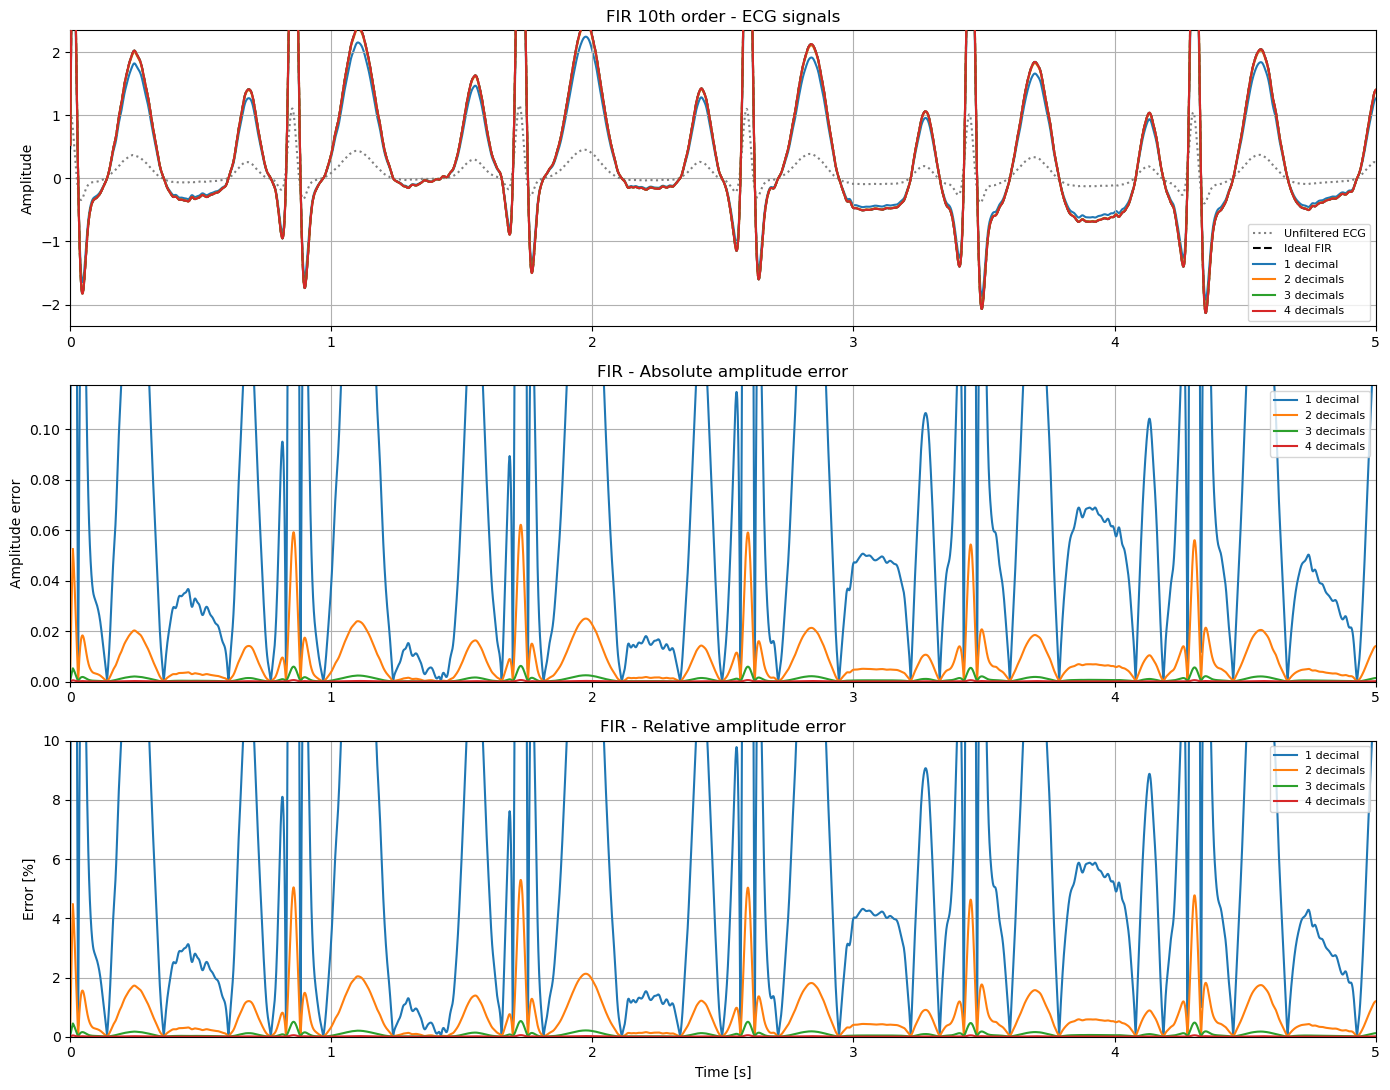


FIR - 10th order
Decimals | Max amplitude error | Max relative error [%]
   1     |      0.630332       |        53.7353        
   2     |      0.063033       |         5.3735        
   3     |      0.006303       |         0.5374        
   4     |      0.000630       |         0.0537        


In [6]:

import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy.signal import lfilter

# --------------------------------------------------
# Generate ECG
# --------------------------------------------------

fs = 1000

ecg = nk.ecg_simulate(
    duration=20,
    sampling_rate=fs,
    heart_rate=70,
    random_state=42
)

time = np.arange(len(ecg)) / fs
reference = np.max(np.abs(ecg))

# --------------------------------------------------
# FIR filter - 10th order
# --------------------------------------------------

# 11 coefficients = 10th order
b = np.full(11, 0.5)

# Ideal FIR filter
y_fir_ideal = lfilter(b, [1], ecg)

# FIR filters with maximum coefficient errors
y_fir_1 = lfilter(b - 0.05, [1], ecg)
y_fir_2 = lfilter(b - 0.005, [1], ecg)
y_fir_3 = lfilter(b - 0.0005, [1], ecg)
y_fir_4 = lfilter(b - 0.00005, [1], ecg)

# Absolute amplitude errors
e_fir_1 = np.abs(y_fir_1 - y_fir_ideal)
e_fir_2 = np.abs(y_fir_2 - y_fir_ideal)
e_fir_3 = np.abs(y_fir_3 - y_fir_ideal)
e_fir_4 = np.abs(y_fir_4 - y_fir_ideal)

# --------------------------------------------------
# Plots
# --------------------------------------------------

fig, ax = plt.subplots(3, 1, figsize=(14, 11))

# FIR - ECG signals
ax[0].plot(time, ecg, ":", color="gray", label="Unfiltered ECG")
ax[0].plot(time, y_fir_ideal, "k--", label="Ideal FIR")

ax[0].plot(time, y_fir_1, label="1 decimal", zorder=1)
ax[0].plot(time, y_fir_2, label="2 decimals", zorder=2)
ax[0].plot(time, y_fir_3, label="3 decimals", zorder=3)
ax[0].plot(time, y_fir_4, label="4 decimals", zorder=4)

ax[0].set_title("FIR 10th order - ECG signals")
ax[0].set_ylabel("Amplitude")
ax[0].set_ylim(-2*reference, 2*reference)

# FIR - Absolute error
ax[1].plot(time, e_fir_1, label="1 decimal")
ax[1].plot(time, e_fir_2, label="2 decimals")
ax[1].plot(time, e_fir_3, label="3 decimals")
ax[1].plot(time, e_fir_4, label="4 decimals")

ax[1].set_title("FIR - Absolute amplitude error")
ax[1].set_ylabel("Amplitude error")
ax[1].set_ylim(0, 0.1*reference)

# FIR - Relative error
ax[2].plot(time, 100*e_fir_1/reference, label="1 decimal")
ax[2].plot(time, 100*e_fir_2/reference, label="2 decimals")
ax[2].plot(time, 100*e_fir_3/reference, label="3 decimals")
ax[2].plot(time, 100*e_fir_4/reference, label="4 decimals")

ax[2].set_title("FIR - Relative amplitude error")
ax[2].set_ylabel("Error [%]")
ax[2].set_ylim(0, 10)
ax[2].set_xlabel("Time [s]")

# General formatting
for axes in ax:
    axes.set_xlim(0, 5)
    axes.grid()
    axes.legend(fontsize=8)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# Maximum errors
# --------------------------------------------------

print("\nFIR - 10th order")
print("Decimals | Max amplitude error | Max relative error [%]")

for i, error in enumerate(
    [e_fir_1, e_fir_2, e_fir_3, e_fir_4], start=1
):
    print(
        f"{i:^8} | "
        f"{np.max(error):^19.6f} | "
        f"{100*np.max(error)/reference:^22.4f}"
    )


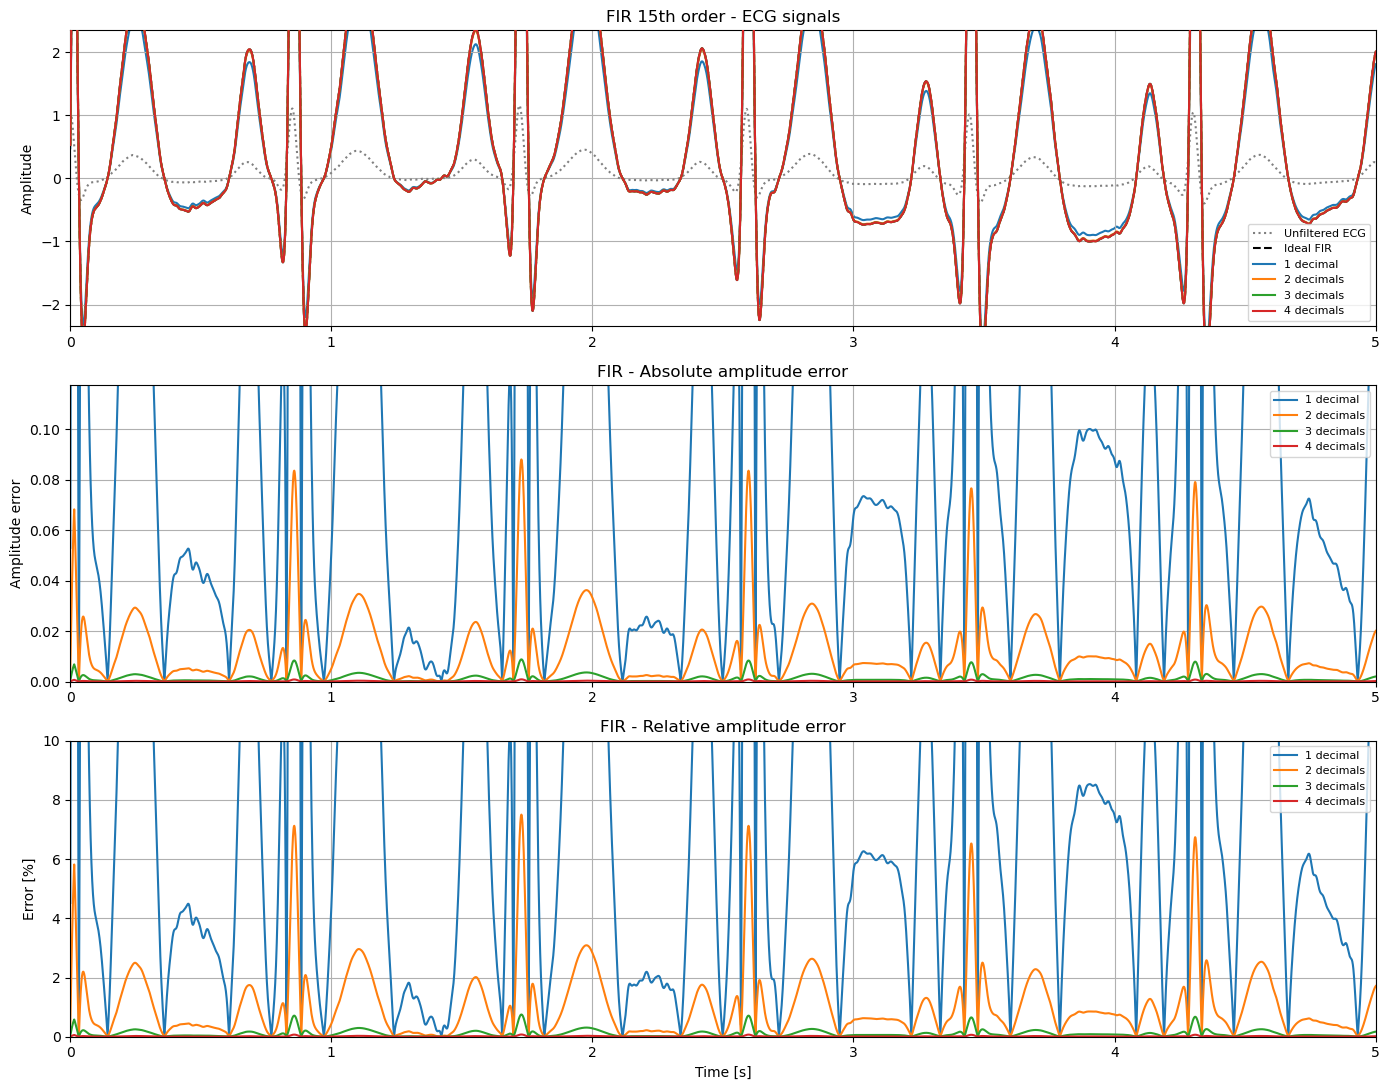


FIR - 15th order
Decimals | Max amplitude error | Max relative error [%]
   1     |      0.893622       |        76.1806        
   2     |      0.089362       |         7.6181        
   3     |      0.008936       |         0.7618        
   4     |      0.000894       |         0.0762        


In [7]:

import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy.signal import lfilter

# --------------------------------------------------
# Generate ECG
# --------------------------------------------------

fs = 1000

ecg = nk.ecg_simulate(
    duration=20,
    sampling_rate=fs,
    heart_rate=70,
    random_state=42
)

time = np.arange(len(ecg)) / fs
reference = np.max(np.abs(ecg))

# --------------------------------------------------
# FIR filter - 15th order
# --------------------------------------------------

# 16 coefficients = 15th order
b = np.full(16, 0.5)

# Ideal FIR filter
y_fir_ideal = lfilter(b, [1], ecg)

# FIR filters with maximum coefficient errors
y_fir_1 = lfilter(b - 0.05, [1], ecg)
y_fir_2 = lfilter(b - 0.005, [1], ecg)
y_fir_3 = lfilter(b - 0.0005, [1], ecg)
y_fir_4 = lfilter(b - 0.00005, [1], ecg)

# Absolute amplitude errors
e_fir_1 = np.abs(y_fir_1 - y_fir_ideal)
e_fir_2 = np.abs(y_fir_2 - y_fir_ideal)
e_fir_3 = np.abs(y_fir_3 - y_fir_ideal)
e_fir_4 = np.abs(y_fir_4 - y_fir_ideal)

# --------------------------------------------------
# Plots
# --------------------------------------------------

fig, ax = plt.subplots(3, 1, figsize=(14, 11))

# FIR - ECG signals
ax[0].plot(time, ecg, ":", color="gray", label="Unfiltered ECG")
ax[0].plot(time, y_fir_ideal, "k--", label="Ideal FIR")

ax[0].plot(time, y_fir_1, label="1 decimal", zorder=1)
ax[0].plot(time, y_fir_2, label="2 decimals", zorder=2)
ax[0].plot(time, y_fir_3, label="3 decimals", zorder=3)
ax[0].plot(time, y_fir_4, label="4 decimals", zorder=4)

ax[0].set_title("FIR 15th order - ECG signals")
ax[0].set_ylabel("Amplitude")
ax[0].set_ylim(-2*reference, 2*reference)

# FIR - Absolute error
ax[1].plot(time, e_fir_1, label="1 decimal")
ax[1].plot(time, e_fir_2, label="2 decimals")
ax[1].plot(time, e_fir_3, label="3 decimals")
ax[1].plot(time, e_fir_4, label="4 decimals")

ax[1].set_title("FIR - Absolute amplitude error")
ax[1].set_ylabel("Amplitude error")
ax[1].set_ylim(0, 0.1*reference)

# FIR - Relative error
ax[2].plot(time, 100*e_fir_1/reference, label="1 decimal")
ax[2].plot(time, 100*e_fir_2/reference, label="2 decimals")
ax[2].plot(time, 100*e_fir_3/reference, label="3 decimals")
ax[2].plot(time, 100*e_fir_4/reference, label="4 decimals")

ax[2].set_title("FIR - Relative amplitude error")
ax[2].set_ylabel("Error [%]")
ax[2].set_ylim(0, 10)
ax[2].set_xlabel("Time [s]")

# General formatting
for axes in ax:
    axes.set_xlim(0, 5)
    axes.grid()
    axes.legend(fontsize=8)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# Maximum errors
# --------------------------------------------------

print("\nFIR - 15th order")
print("Decimals | Max amplitude error | Max relative error [%]")

for i, error in enumerate(
    [e_fir_1, e_fir_2, e_fir_3, e_fir_4], start=1
):
    print(
        f"{i:^8} | "
        f"{np.max(error):^19.6f} | "
        f"{100*np.max(error)/reference:^22.4f}"
    )


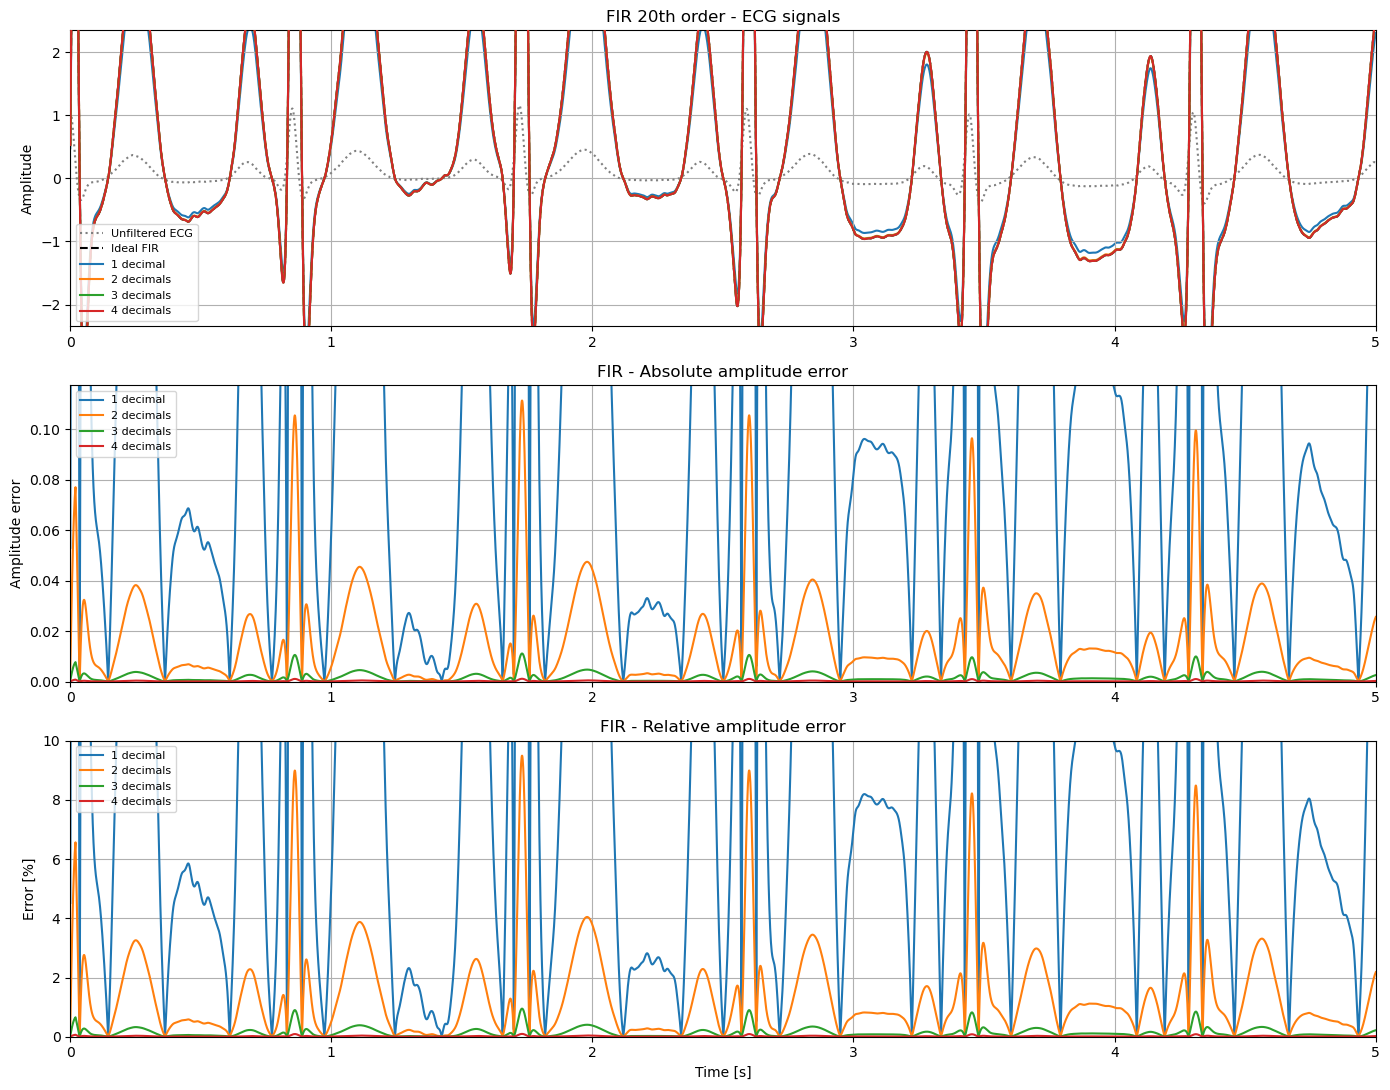


FIR - 20th order
Decimals | Max amplitude error | Max relative error [%]
   1     |      1.131311       |        96.4434        
   2     |      0.113131       |         9.6443        
   3     |      0.011313       |         0.9644        
   4     |      0.001131       |         0.0964        


In [8]:

import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy.signal import lfilter

# --------------------------------------------------
# Generate ECG
# --------------------------------------------------

fs = 1000

ecg = nk.ecg_simulate(
    duration=20,
    sampling_rate=fs,
    heart_rate=70,
    random_state=42
)

time = np.arange(len(ecg)) / fs
reference = np.max(np.abs(ecg))

# --------------------------------------------------
# FIR filter - 20th order
# --------------------------------------------------

# 21 coefficients = 20th order
b = np.full(21, 0.5)

# Ideal FIR filter
y_fir_ideal = lfilter(b, [1], ecg)

# FIR filters with maximum coefficient errors
y_fir_1 = lfilter(b - 0.05, [1], ecg)
y_fir_2 = lfilter(b - 0.005, [1], ecg)
y_fir_3 = lfilter(b - 0.0005, [1], ecg)
y_fir_4 = lfilter(b - 0.00005, [1], ecg)

# Absolute amplitude errors
e_fir_1 = np.abs(y_fir_1 - y_fir_ideal)
e_fir_2 = np.abs(y_fir_2 - y_fir_ideal)
e_fir_3 = np.abs(y_fir_3 - y_fir_ideal)
e_fir_4 = np.abs(y_fir_4 - y_fir_ideal)

# --------------------------------------------------
# Plots
# --------------------------------------------------

fig, ax = plt.subplots(3, 1, figsize=(14, 11))

# FIR - ECG signals
ax[0].plot(time, ecg, ":", color="gray", label="Unfiltered ECG")
ax[0].plot(time, y_fir_ideal, "k--", label="Ideal FIR")

ax[0].plot(time, y_fir_1, label="1 decimal", zorder=1)
ax[0].plot(time, y_fir_2, label="2 decimals", zorder=2)
ax[0].plot(time, y_fir_3, label="3 decimals", zorder=3)
ax[0].plot(time, y_fir_4, label="4 decimals", zorder=4)

ax[0].set_title("FIR 20th order - ECG signals")
ax[0].set_ylabel("Amplitude")
ax[0].set_ylim(-2*reference, 2*reference)

# FIR - Absolute error
ax[1].plot(time, e_fir_1, label="1 decimal")
ax[1].plot(time, e_fir_2, label="2 decimals")
ax[1].plot(time, e_fir_3, label="3 decimals")
ax[1].plot(time, e_fir_4, label="4 decimals")

ax[1].set_title("FIR - Absolute amplitude error")
ax[1].set_ylabel("Amplitude error")
ax[1].set_ylim(0, 0.1*reference)

# FIR - Relative error
ax[2].plot(time, 100*e_fir_1/reference, label="1 decimal")
ax[2].plot(time, 100*e_fir_2/reference, label="2 decimals")
ax[2].plot(time, 100*e_fir_3/reference, label="3 decimals")
ax[2].plot(time, 100*e_fir_4/reference, label="4 decimals")

ax[2].set_title("FIR - Relative amplitude error")
ax[2].set_ylabel("Error [%]")
ax[2].set_ylim(0, 10)
ax[2].set_xlabel("Time [s]")

# General formatting
for axes in ax:
    axes.set_xlim(0, 5)
    axes.grid()
    axes.legend(fontsize=8)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# Maximum errors
# --------------------------------------------------

print("\nFIR - 20th order")
print("Decimals | Max amplitude error | Max relative error [%]")

for i, error in enumerate(
    [e_fir_1, e_fir_2, e_fir_3, e_fir_4], start=1
):
    print(
        f"{i:^8} | "
        f"{np.max(error):^19.6f} | "
        f"{100*np.max(error)/reference:^22.4f}"
    )


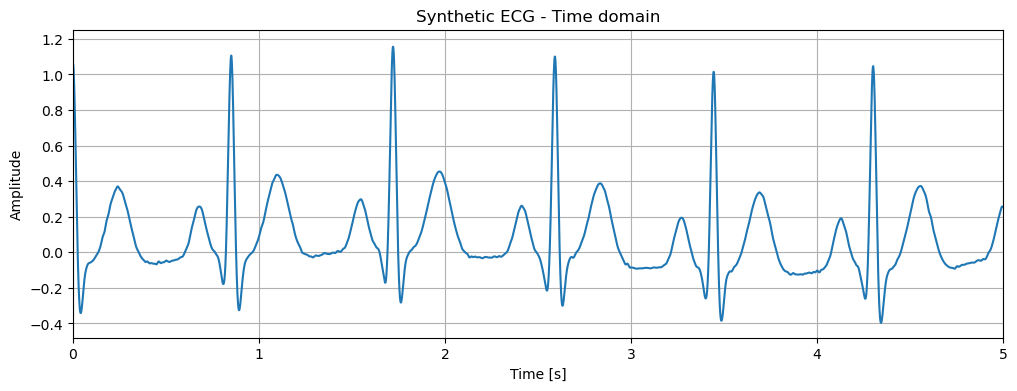

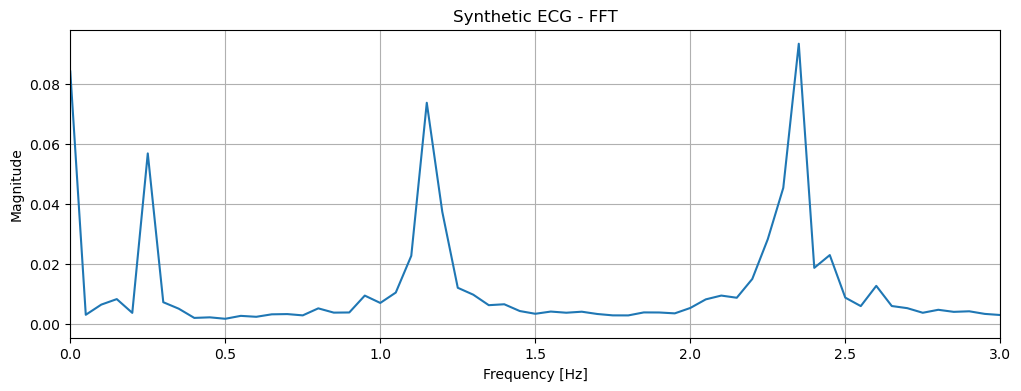

In [14]:

import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk

# --------------------------------------------------
# Generate ECG
# --------------------------------------------------

fs = 1000
duration = 20

ecg = nk.ecg_simulate(
    duration=duration,
    sampling_rate=fs,
    heart_rate=70,
    random_state=42
)

time = np.arange(len(ecg)) / fs

# --------------------------------------------------
# FFT
# --------------------------------------------------

fft = np.fft.rfft(ecg)
frequencies = np.fft.rfftfreq(len(ecg), d=1/fs)

magnitude = np.abs(fft) / len(ecg)
magnitude[1:-1] *= 2

# --------------------------------------------------
# Plots
# --------------------------------------------------

plt.figure(figsize=(12, 4))
plt.plot(time, ecg)
plt.title("Synthetic ECG - Time domain")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.xlim(0, 5)
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(frequencies, magnitude)
plt.title("Synthetic ECG - FFT")
plt.xlabel("Frequency [Hz]")
plt.ylabel("Magnitude")
plt.xlim(0, 3)
plt.grid()
plt.show()


1 decimals: Unstable filter
2 decimals: Unstable filter
3 decimals: Unstable filter
4 decimals: Max relative error = 16.9668%


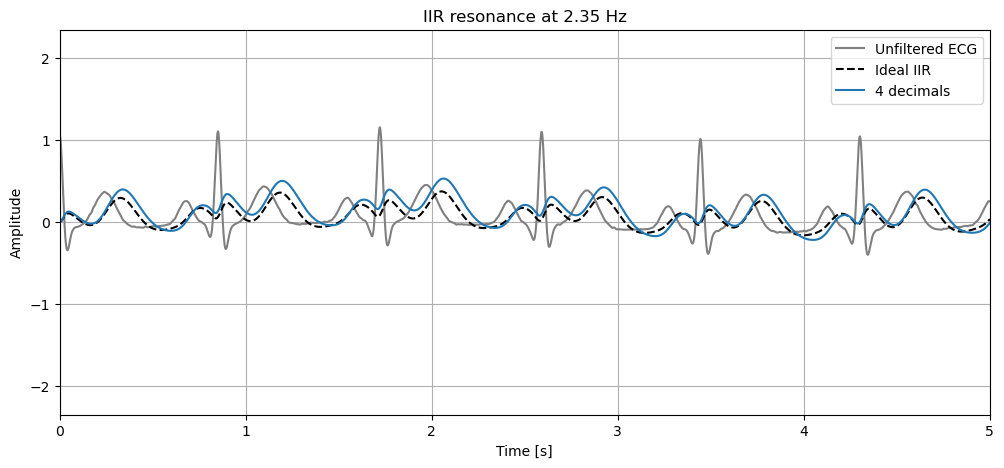

In [15]:

import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy.signal import lfilter

# --------------------------------------------------
# Generate ECG
# --------------------------------------------------

fs = 1000

ecg = nk.ecg_simulate(
    duration=20,
    sampling_rate=fs,
    heart_rate=70,
    random_state=42
)

time = np.arange(len(ecg)) / fs
reference = np.max(np.abs(ecg))

# --------------------------------------------------
# IIR resonator - 2nd order
# --------------------------------------------------

f0 = 2.35
r = 0.99
omega = 2 * np.pi * f0 / fs

# Normalize gain at the resonance frequency
a = np.array([1.0, -2*r*np.cos(omega), r**2])
b = np.array([np.abs(np.polyval(a, np.exp(1j*omega)))])

y_ideal = lfilter(b, a, ecg)

# --------------------------------------------------
# Coefficient error simulations
# --------------------------------------------------

plt.figure(figsize=(12, 5))
plt.plot(time, ecg, color="gray", label="Unfiltered ECG")
plt.plot(time, y_ideal, "k--", label="Ideal IIR")

for decimals in [1, 2, 3, 4]:

    error = 0.5 * 10**(-decimals)

    # Example error direction
    b_error = b + error
    a_error = a.copy()
    a_error[1:] -= error

    poles = np.roots(a_error)

    if np.any(np.abs(poles) >= 1):
        print(f"{decimals} decimals: Unstable filter")
        continue

    y_error = lfilter(b_error, a_error, ecg)

    absolute_error = np.abs(y_error - y_ideal)

    print(
        f"{decimals} decimals: "
        f"Max relative error = "
        f"{100*np.max(absolute_error)/reference:.4f}%"
    )

    plt.plot(time, y_error, label=f"{decimals} decimals")

plt.xlim(0, 5)
plt.ylim(-2*reference, 2*reference)
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("IIR resonance at 2.35 Hz")
plt.grid()
plt.legend()
plt.show()
